1. PepGate Objective 

Question: Does CycPeptMPDB contain enough cyclic peptides with measured permeability that can be represented by PepGate's constrained backbone edit space?

PepGate keeps the sidechain scaffold fixed and represents each backbone position as one of four states:
- none
- D
- NMe
- D+NMe
This notebook reproduces the feasibility audit behind analysis/matched_backbone.py and visualizes where the usable dataset comes from.

2. Load CycPeptMPDB

In [4]:
from pathlib import Path
import sys
import ast
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def find_repo_root():
    cwd = Path.cwd().resolve()
    for candidate in [cwd, *cwd.parents]:
        if (candidate / "src").exists() and (candidate / "analysis").exists():
            return candidate
    raise RuntimeError(
        "Could not find the PepGate repository root. "
        "Open this notebook from inside the PepGate repository."
    )

ROOT = find_repo_root()
SRC = ROOT / "src"
OUTPUTS = ROOT / "outputs"
DATA = ROOT / "data"

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

print("PepGate root:", ROOT)

PepGate root: /Users/yeritmaryrodriguezdelgado/Desktop/PEPGATE_YRD


3. Dataset overview
Load the raw CycPeptMPDB tables
The notebook expects the same files used by the analysis pipeline:
- data/raw/CycPeptMPDB_Peptide_All.csv
- data/raw/CycPeptMPDB_Monomer_All.csv

4. PAMPA availability



In [5]:
from backbone import (
    annotate_sequence,
    build_monomer_map,
    canonicalize_ring,
    load_monomer_table,
    parse_iupac_backbone,
)

PEPTIDE_PATH = DATA / "raw" / "CycPeptMPDB_Peptide_All.csv"
MONOMER_PATH = DATA / "raw" / "CycPeptMPDB_Monomer_All.csv"

assert PEPTIDE_PATH.exists(), f"Missing {PEPTIDE_PATH}"
assert MONOMER_PATH.exists(), f"Missing {MONOMER_PATH}"

peptides_raw = pd.read_csv(PEPTIDE_PATH, low_memory=False)
monomers = load_monomer_table(MONOMER_PATH)

print(f"Peptides: {len(peptides_raw):,}")
print(f"Monomers: {len(monomers):,}")
display(peptides_raw.head())

Peptides: 8,466
Monomers: 385


,ID,Source,Year,Version,Original_Name_in_Source_Literature,Structurally_Unique_ID,Same_Peptides_ID,Same_Peptides_Source,Same_Peptides_Permeability,Same_Peptides_Assay,...,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea,PC1,PC2,CHCl3_3DPSA,H2O_3DPSA
0,1,2006_Rezai_1,2006,1.0,Cyclosporine A,1,"[22, 932, 981, 1822, 1862, 2356, 7188, 7353]","['2011_White', '2015_Ahlbach', '2015_Bockus_1'...","[['-5.96'], ['-5.01'], ['-5.96'], ['-6.20'], [...","[['RRCK'], ['PAMPA'], ['RRCK'], ['PAMPA'], ['R...",...,0,0,0,0,0,0,-6.620416,-0.186784,174.0,173.0
1,2,2006_Rezai_1,2006,1.0,compound.1,2,[1048],['2015_Wang'],"[['-5.46', '-4.92']]","[['PAMPA', 'Caco2']]",...,0,0,0,0,0,0,2.443604,-1.286947,163.0,165.0
2,3,2006_Rezai_1,2006,1.0,compound.2,3,NaN,NaN,NaN,NaN,...,0,0,0,0,0,0,2.443604,-1.286947,163.0,162.0
3,4,2006_Rezai_1,2006,1.0,compound.3,4,NaN,NaN,NaN,NaN,...,0,0,0,0,0,0,2.443604,-1.286947,146.0,142.0
4,5,2006_Rezai_1,2006,1.0,compound.4,5,[1045],['2015_Wang'],"[['-5.79', '-5.84']]","[['PAMPA', 'Caco2']]",...,0,0,0,0,0,0,2.443604,-1.286947,164.0,165.0


5. Cyclic peptide filtering

The parser removes only the D-stereochemistry and N-methylation prefixes from the backbone description while preserving side-chain substitutions such as Ala(tBu).

6. Backbone-state parser

In [6]:
examples = [
    "H-Ala-OH",
    "H-D-Ala-OH",
    "Me-Ala-OH",
    "Me-D-Ala-OH",
    "H-Ala(tBu)-OH",
    "H-D-Ala(tBu)-OH",
]

parser_demo = pd.DataFrame(
    [
        {
            "IUPAC_Condensed": x,
            "parsed_sidechain": parse_iupac_backbone(x)[0],
            "backbone_state": parse_iupac_backbone(x)[1],
        }
        for x in examples
    ]
)

display(parser_demo)

,IUPAC_Condensed,parsed_sidechain,backbone_state
0,H-Ala-OH,Ala,none
1,H-D-Ala-OH,Ala,D
2,Me-Ala-OH,Ala,NMe
3,Me-D-Ala-OH,Ala,D+NMe
4,H-Ala(tBu)-OH,Ala(tBu),none
5,H-D-Ala(tBu)-OH,Ala(tBu),D


7. Supported vs unsupported monomers
Filter to cyclic peptides with PAMPA measurements and annotate the backbone

In [7]:
monomer_map = build_monomer_map(monomers)

cyclic_pampa = peptides_raw[
    (peptides_raw["Molecule_Shape"] == "Circle")
    & peptides_raw["PAMPA"].notna()
].copy()

records = []

for _, row in cyclic_pampa.iterrows():
    annotation = annotate_sequence(row["Sequence"], monomer_map)

    record = {
        "ID": row["ID"],
        "Source": row["Source"],
        "PAMPA": row["PAMPA"],
        "Sequence": row["Sequence"],
        "HELM": row["HELM"],
        "Monomer_Length": row["Monomer_Length"],
        "supported": annotation["supported"],
        "reason": annotation["reason"],
    }

    if annotation["supported"]:
        sidechains, backbone = canonicalize_ring(
            annotation["sidechains"],
            annotation["backbone"],
        )
        record["sidechain_signature"] = sidechains
        record["backbone_pattern"] = backbone
    else:
        record["sidechain_signature"] = None
        record["backbone_pattern"] = None

    records.append(record)

annotated = pd.DataFrame(records)
supported = annotated[annotated["supported"]].copy()
excluded = annotated[~annotated["supported"]].copy()

summary = pd.DataFrame({
    "stage": [
        "All CycPeptMPDB peptides",
        "Cyclic + PAMPA",
        "PepGate-supported",
        "Excluded from edit space",
    ],
    "count": [
        len(peptides_raw),
        len(cyclic_pampa),
        len(supported),
        len(excluded),
    ],
})

display(summary)

,stage,count
0,All CycPeptMPDB peptides,8466
1,Cyclic + PAMPA,4994
2,PepGate-supported,2097
3,Excluded from edit space,2897


8. PepGate-compatible peptide count

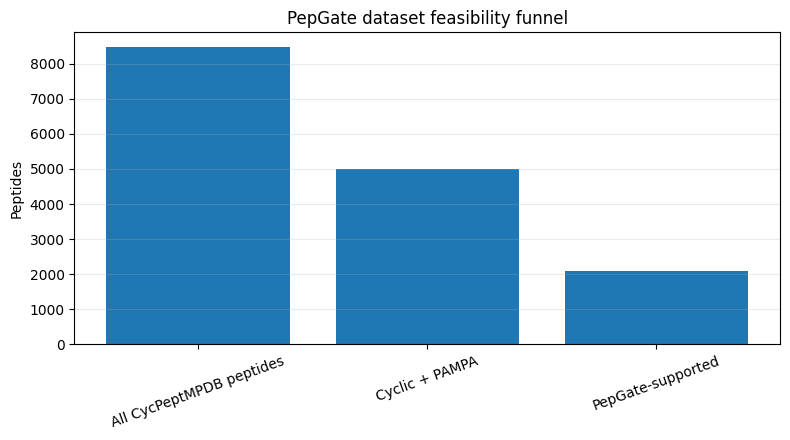

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_df = summary.iloc[:3]
ax.bar(plot_df["stage"], plot_df["count"])
ax.set_ylabel("Peptides")
ax.set_title("PepGate dataset feasibility funnel")
ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

Why are peptides excluded ?

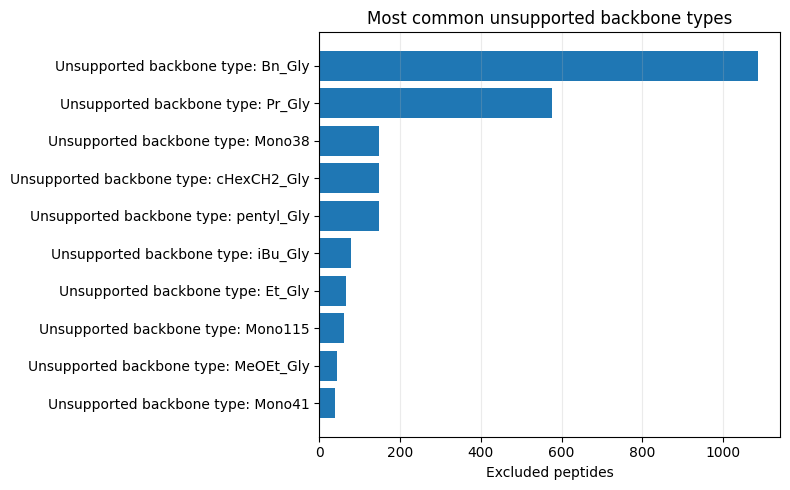

,count
reason,
Unsupported backbone type: Mono41,40
Unsupported backbone type: MeOEt_Gly,43
Unsupported backbone type: Mono115,60
Unsupported backbone type: Et_Gly,66
Unsupported backbone type: iBu_Gly,78
Unsupported backbone type: pentyl_Gly,148
Unsupported backbone type: cHexCH2_Gly,148
Unsupported backbone type: Mono38,148
Unsupported backbone type: Pr_Gly,577


In [9]:
exclusion_counts = (
    excluded["reason"]
    .value_counts()
    .head(10)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(exclusion_counts.index, exclusion_counts.values)
ax.set_xlabel("Excluded peptides")
ax.set_title("Most common unsupported backbone types")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

display(exclusion_counts.rename("count").to_frame())

Ring-size distribution of supported peptides

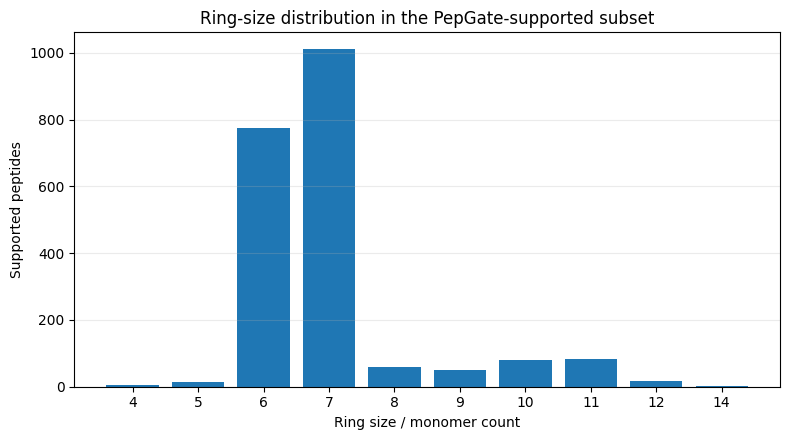

In [10]:
ring_counts = (
    supported["Monomer_Length"]
    .value_counts()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(ring_counts.index.astype(str), ring_counts.values)
ax.set_xlabel("Ring size / monomer count")
ax.set_ylabel("Supported peptides")
ax.set_title("Ring-size distribution in the PepGate-supported subset")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

Build matched side-chain parent series
Measurements are grouped by publication source + canonicalized side-chain signature. Peptides in the same group have the same side-chain scaffold but may differ in backbone modification pattern.

In [11]:
series = (
    supported
    .groupby(["Source", "sidechain_signature"])
    .agg(
        n_peptides=("ID", "nunique"),
        n_patterns=("backbone_pattern", "nunique"),
        ring_size=("Monomer_Length", "first"),
    )
    .reset_index()
)

thresholds = [2, 3, 5, 10]
threshold_summary = pd.DataFrame({
    "minimum_patterns": thresholds,
    "parent_series": [(series["n_patterns"] >= k).sum() for k in thresholds],
})

display(threshold_summary)

,minimum_patterns,parent_series
0,2,56
1,3,25
2,5,19
3,10,9


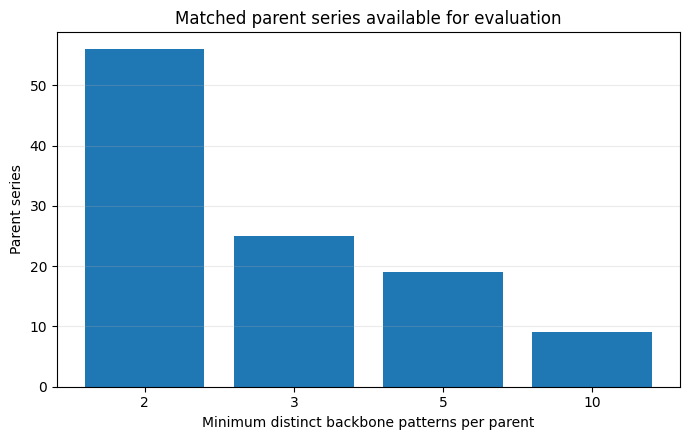

In [12]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(threshold_summary["minimum_patterns"].astype(str), threshold_summary["parent_series"])
ax.set_xlabel("Minimum distinct backbone patterns per parent")
ax.set_ylabel("Parent series")
ax.set_title("Matched parent series available for evaluation")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

9. Summary

Takeaway
This notebook establishes whether the constrained PepGate representation is supported by the dataset. The analysis should be reported as a feasibility audit, not as a performance result.

The generated CSVs from the script version remain the canonical pipeline outputs:
- outputs/peptide_backbone_annotations.csv
- outputs/matched_parent_series.csv